# Transfer learning 1 : MobileNetV2 (ImageNet)

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from results_utils import DATA_DIR, MODELS_DIR, RESULTS_DIR, callbacks_paths, save_results

tf.keras.utils.set_random_seed(42)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 5
LR = 1e-3
RETRAIN = False

## 1. Chargement des images


In [18]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "valid", image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_ds.class_names
print(class_names)

Found 1468 files belonging to 10 classes.
Found 50 files belonging to 10 classes.
Found 50 files belonging to 10 classes.
['basketball', 'bowling', 'football', 'judo', 'rowing', 'ski jumping', 'surfing', 'swimming', 'tennis', 'track bicycle']


## 2. modèle pré-entraîné

In [19]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

## 3.  modèle complet


In [20]:
inputs = keras.Input(shape=IMG_SIZE + (3,))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.summary()  # seuls les poids de la dernière Dense sont entraînables

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Entraînement (ou chargement)

Si `models/tl_mobilenetv2_simple_best.keras` existe déjà, on **charge** le modèle au lieu de le réentraîner. Mets `RETRAIN = True` dans la cellule des paramètres pour forcer un nouvel entraînement.

In [21]:
MODEL_NAME = "tl_mobilenetv2_simple"
best_model_path, history_path = callbacks_paths(MODEL_NAME)

if best_model_path.exists() and not RETRAIN:
    model = keras.models.load_model(best_model_path)
    trained = False
    print(f"Modèle chargé depuis {best_model_path.name} : pas de réentraînement")
else:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss="sparse_categorical_crossentropy",  # labels entiers (0..9)
        metrics=["accuracy"],
    )
    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[
            callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
            callbacks.CSVLogger(history_path),
        ],
    )
    model.save(best_model_path)  # sauvegarde juste après l'entraînement
    trained = True
    print(f"Modèle sauvegardé dans {best_model_path.name}")

# L'historique est relu depuis le CSV : il est disponible même quand on charge le modèle
history = pd.read_csv(history_path)

Modèle chargé depuis tl_mobilenetv2_simple_best.keras : pas de réentraînement


## 5. Courbes d'apprentissage

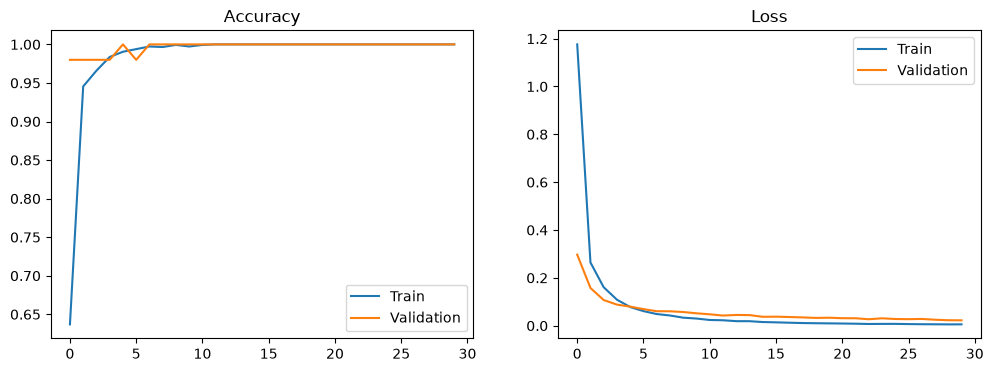

In [22]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history["accuracy"], label="Train")
plt.plot(history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()
plt.show()

## 6. Évaluation sur le test

Après un nouvel entraînement, `save_results` affiche le rapport par classe et ajoute le run à `results/runs.csv`. Si le modèle a seulement été chargé, on l'évalue sans ajouter de ligne, pour ne pas dupliquer le run dans `runs.csv`.

In [23]:
if trained:
    params = {"epochs": EPOCHS, "lr": LR, "patience": PATIENCE, "batch_size": BATCH_SIZE, "filters": "MobileNetV2 frozen",
              "dropout": 0.2, "augment": False}
    y_true, y_pred, probs, test_acc = save_results(MODEL_NAME, model, test_ds, class_names, params)
else:
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f"Test accuracy: {test_acc:.2%}")

Test accuracy: 100.00%


## 7. Validation croisée (k-fold)

In [24]:
from sklearn.model_selection import StratifiedKFold

K = 5

# train + valid, sans mélange (StratifiedKFold s'en charge)
cv_train = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
cv_valid = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "valid", image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
cv_ds = cv_train.concatenate(cv_valid)

# Extracteur de features : même début que le modèle, sans la tête
fe_inputs = keras.Input(shape=IMG_SIZE + (3,))
x = tf.keras.applications.mobilenet_v2.preprocess_input(fe_inputs)
x = base_model(x, training=False)
fe_outputs = layers.GlobalAveragePooling2D()(x)
feature_extractor = keras.Model(fe_inputs, fe_outputs)

features_path = MODELS_DIR / "tl_mobilenetv2_features.npz"
if features_path.exists() and not RETRAIN:
    data = np.load(features_path)
    X, y = data["X"], data["y"]
    print(f"Features chargées depuis {features_path.name}")
else:
    X = feature_extractor.predict(cv_ds)                      # (1518, 1280)
    y = np.concatenate([labels.numpy() for _, labels in cv_ds])
    np.savez(features_path, X=X, y=y)
    print(f"Features sauvegardées dans {features_path.name}")
print(X.shape, y.shape)

Found 1468 files belonging to 10 classes.
Found 50 files belonging to 10 classes.
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 201ms/step
Features sauvegardées dans tl_mobilenetv2_features.npz
(1518, 1280) (1518,)


In [25]:
def build_head():
    # La même tête que dans le modèle complet : Dropout + Dense softmax
    head = keras.Sequential([
        keras.Input(shape=(X.shape[1],)),
        layers.Dropout(0.2),
        layers.Dense(len(class_names), activation="softmax"),
    ])
    head.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return head

skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)
fold_results = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
    tf.keras.utils.set_random_seed(42)
    head = build_head()  # nouvelle tête à chaque fold : on repart de zéro
    h = head.fit(
        X[tr_idx], y[tr_idx],
        validation_data=(X[va_idx], y[va_idx]),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
        verbose=0,
    )
    best = int(np.argmin(h.history["val_loss"]))
    fold_results.append({"fold": fold, "best_epoch": best + 1,
                         "val_acc": h.history["val_accuracy"][best],
                         "val_loss": h.history["val_loss"][best]})
    print(f"Fold {fold}: val_acc = {fold_results[-1]['val_acc']:.2%} (best epoch {best + 1})")

cv = pd.DataFrame(fold_results)
cv.to_csv(RESULTS_DIR / "tl_mobilenetv2_simple_cv.csv", index=False)
print(f"\nCV accuracy ({K}-fold): {cv['val_acc'].mean():.2%} ± {cv['val_acc'].std():.2%}")

Fold 1: val_acc = 98.36% (best epoch 30)
Fold 2: val_acc = 97.04% (best epoch 28)
Fold 3: val_acc = 97.70% (best epoch 29)
Fold 4: val_acc = 98.35% (best epoch 25)
Fold 5: val_acc = 98.68% (best epoch 29)

CV accuracy (5-fold): 98.02% ± 0.66%


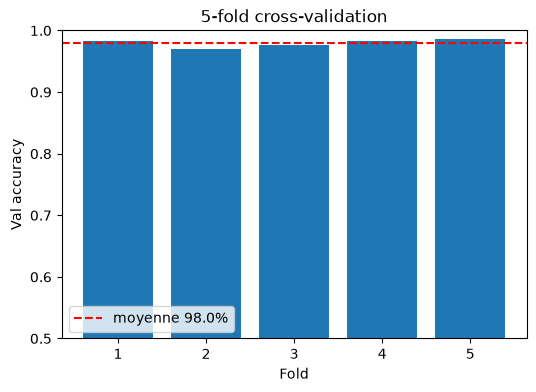

In [26]:
plt.figure(figsize=(6, 4))
plt.bar(cv["fold"], cv["val_acc"])
plt.axhline(cv["val_acc"].mean(), color="red", linestyle="--", label=f"moyenne {cv['val_acc'].mean():.1%}")
plt.ylim(0.5, 1)
plt.xlabel("Fold")
plt.ylabel("Val accuracy")
plt.title(f"{K}-fold cross-validation")
plt.legend()
plt.show()